# TabOrder: order recovery, imputation, and intervention

This introduction runs on CPU, uses the two released checkpoints, and downloads
no models or data by default. Install once from the repository root:

```sh
python -m pip install -e '.[notebook]'
jupyter lab examples/intro.ipynb
```

**What is reproduced?** Section 1 reconstructs Figure 1 from the exact saved
prediction values used by the paper, using Matplotlib instead of TikZ.
Sections 2–4 run fresh, small experiments: synthetic causal-order recovery,
missing-value imputation, and a paired intervention on a three-node chain.
The fresh runs use the released additive GP checkpoint; Figure 1 originally
used the non-additive GP checkpoint. The notebook distinguishes the two.

The imputation section also exercises the CC18/CTR23 fine-tuned weights on an
offline real table. It is a usage example, not the full CC18/CTR23 benchmark.


In [1]:
from pathlib import Path
import hashlib
import json
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

# Allow launching Jupyter from the repo root or examples/.
candidates = [Path.cwd(), Path.cwd().parent, Path.cwd() / "release"]
ROOT = next((p for p in candidates if (p / "checkpoints/taborder-gp-small.pth").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Launch this notebook from the release repository root or examples/.")
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "examples"))
from taborder import load_model
from intro_utils import (
    synthetic_order_experiment, imputation_experiment,
    intervention_experiment, plot_paper_figure1,
)

# Existing research masks trigger this known PyTorch deprecation warning.
warnings.filterwarnings("ignore", message="Support for mismatched.*", category=UserWarning)
SEED = 42
DEVICE = "cpu"  # Set to "cuda" if available.
RUN_TABPFN = False  # Optional fresh baseline; see Section 4.
TABPFN_MODEL_PATH = None  # Optional path to a compatible, locally downloaded model.
ORDER_SEEDS = range(5)
IMPUTATION_SEEDS = range(3)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(min(4, torch.get_num_threads()))
OUT = ROOT / "outputs/intro"
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.size": 10, "figure.dpi": 120, "savefig.dpi": 180})
gp_model = load_model(ROOT / "checkpoints/taborder-gp-small.pth", DEVICE)
fine_model = load_model(ROOT / "checkpoints/taborder-cc18-ctr23.pth", DEVICE)
print(f"Device: {DEVICE}; PyTorch {torch.__version__}; NumPy {np.__version__}")


Device: cpu; PyTorch 2.10.0; NumPy 2.4.1


## 1. Recreate Figure 1 from the paper's prediction data

The task is to predict the mediator $Y$ in $X \to Y \to Z$. Green points
are observational queries; orange points have an intervention replacing the
mechanism for $Z$ with independent noise. The black curve is $f(X)$.

The following cell uses all 500 saved query predictions. It does **not** run
TabPFN or TabOrder again. This makes the published plot reproducible without
additional checkpoint downloads. The data manifest records the original
experiment, checkpoint, seed, and SHA-256 checksum. The historical TabPFN package
and model versions were not recorded; no version is inferred from today's defaults.


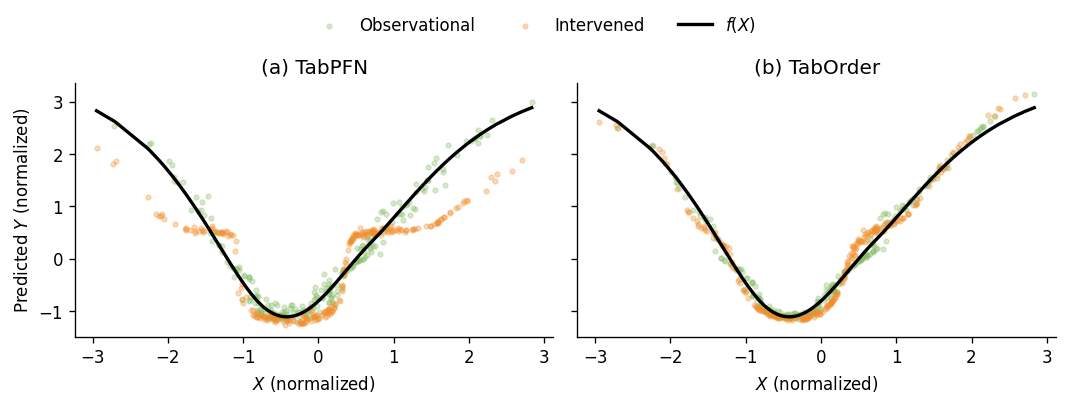

                      method     condition    mse
  TabPFN (paper predictions) Observational 0.0152
  TabPFN (paper predictions)    Intervened 0.2369
TabOrder (paper predictions) Observational 0.0231
TabOrder (paper predictions)    Intervened 0.0670


In [2]:
data_path = ROOT / "examples/data/figure1_predictions.csv"
figure_manifest = json.loads((data_path.parent / "figure1_manifest.json").read_text())
assert hashlib.sha256(data_path.read_bytes()).hexdigest() == figure_manifest["sha256"]
paper_predictions = pd.read_csv(data_path)
assert len(paper_predictions) == 500
fig = plot_paper_figure1(paper_predictions)
fig.savefig(OUT / "figure1.png", bbox_inches="tight")
fig.savefig(OUT / "figure1.pdf", bbox_inches="tight")
plt.show()

paper_metrics = []
for name, column in [("TabPFN (paper predictions)", "y_pred_tabpfn"), ("TabOrder (paper predictions)", "y_pred_cfm")]:
    for intervention, group in paper_predictions.groupby("is_intervened"):
        mse = np.mean((group[column] - group["y_true"]) ** 2)
        paper_metrics.append(dict(method=name, condition="Intervened" if intervention else "Observational", mse=mse))
paper_metrics = pd.DataFrame(paper_metrics)
paper_metrics.to_csv(OUT / "figure1_metrics.csv", index=False)
print(paper_metrics.to_string(index=False, float_format=lambda x: f"{x:.4f}"))


## 2. Recover causal orders from synthetic data

Generate new 5-variable additive GP SCMs using the released training prior.
Evaluate the same seeds with 0%, 20%, and 40% missing entries. Topological
divergence is the fraction of directed edges whose order is reversed: 0 is
perfect and a random ordering has expected divergence 0.5.

The baseline averages 32 independently sampled orders per table. Error bars
are standard errors across the five dataset seeds. These are a small executable
experiment, not the paper's full order-discovery comparison.


                        mean     sem
method       masking                
Random order 0.0      0.4972  0.0150
             0.2      0.4972  0.0150
             0.4      0.4972  0.0150
TabOrder     0.0      0.1507  0.0470
             0.2      0.1471  0.0419
             0.4      0.2250  0.0867


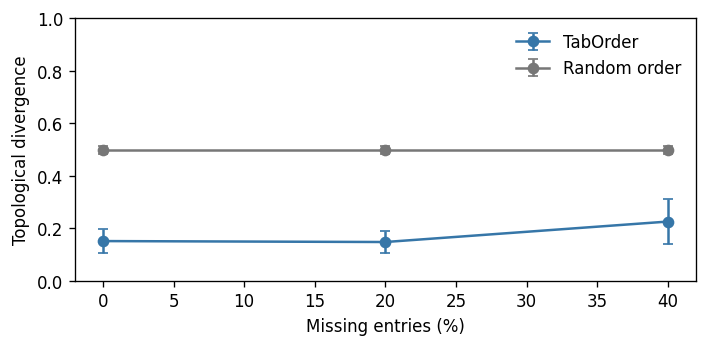

In [3]:
order_results = synthetic_order_experiment(gp_model, seeds=ORDER_SEEDS)
order_results.to_csv(OUT / "synthetic_order.csv", index=False)
order_summary = order_results.groupby(["method", "masking"])["divergence"].agg(["mean", "sem"])
print(order_summary.round(4).to_string())
fig, ax = plt.subplots(figsize=(6, 3))
for method, color in [("TabOrder", "#3676a8"), ("Random order", "#777777")]:
    group = order_summary.loc[method]
    ax.errorbar(100 * group.index.to_numpy(), group["mean"], yerr=group["sem"],
                marker="o", capsize=3, label=method, color=color)
ax.set(xlabel="Missing entries (%)", ylabel="Topological divergence", ylim=(0, 1))
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(OUT / "synthetic_order.png", bbox_inches="tight")
plt.show()


## 3. Impute missing values with both released checkpoints

Use a new synthetic GP table and scikit-learn's bundled diabetes feature table
(the regression target is excluded). Randomly select 128 context rows and 64
query rows, with 20% missing entries. Only the context's observed values fit
normalization and the KNN baseline. Hidden entries are replaced with NaN before
encoding, and errors are computed only on masked query entries.

Compare context-mean filling, KNN, the additive GP model, and the CC18/CTR23
fine-tuned model using identical masks. RMSE is measured in context-standardized
units so columns with different scales are comparable. The diabetes table is an
offline usage example; these numbers are not CC18/CTR23 aggregate results or an
assessment of whether a dataset was excluded from historical fine-tuning.


                                                     mean     sem
dataset                       method                             
Diabetes (offline real table) Context mean         1.0001  0.0414
                              KNN (context only)   0.8507  0.0192
                              TabOrder CC18/CTR23  0.8408  0.0167
                              TabOrder GP          0.9230  0.0181
Synthetic GP                  Context mean         1.0394  0.0547
                              KNN (context only)   0.8446  0.0620
                              TabOrder CC18/CTR23  0.8502  0.0510
                              TabOrder GP          0.8757  0.0580


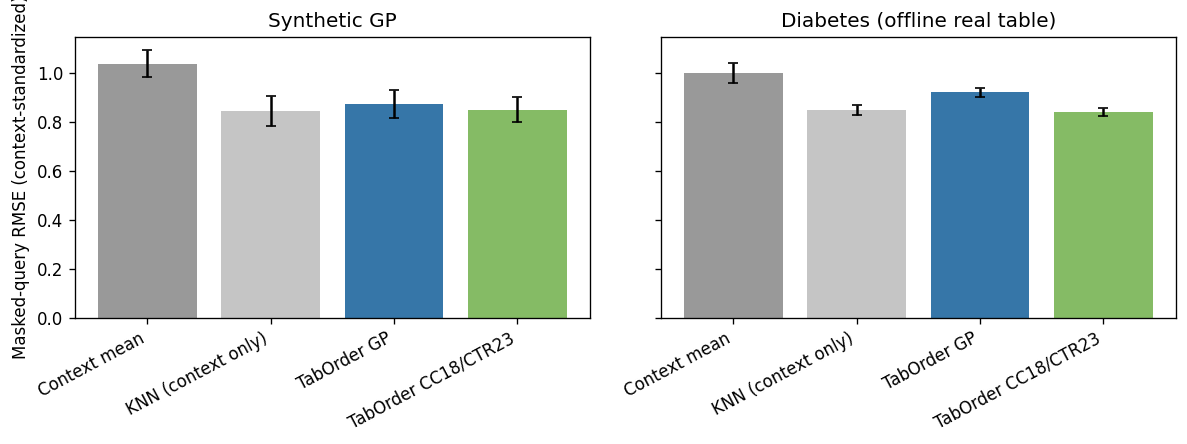

In [4]:
imputation_results = imputation_experiment(
    {"TabOrder GP": gp_model, "TabOrder CC18/CTR23": fine_model}, seeds=IMPUTATION_SEEDS,
)
imputation_results.to_csv(OUT / "imputation.csv", index=False)
imputation_summary = imputation_results.groupby(["dataset", "method"])["normalized_rmse"].agg(["mean", "sem"])
print(imputation_summary.round(4).to_string())
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
methods = ["Context mean", "KNN (context only)", "TabOrder GP", "TabOrder CC18/CTR23"]
for ax, dataset in zip(axes, imputation_results["dataset"].unique()):
    group = imputation_summary.loc[dataset].loc[methods]
    ax.bar(range(len(methods)), group["mean"], yerr=group["sem"], capsize=3,
           color=["#999999", "#c5c5c5", "#3676a8", "#85bb65"])
    ax.set_xticks(range(len(methods)), methods, rotation=28, ha="right")
    ax.set_title(dataset)
axes[0].set_ylabel("Masked-query RMSE (context-standardized)")
fig.tight_layout()
fig.savefig(OUT / "imputation.png", bbox_inches="tight")
plt.show()


## 4. Run a fresh intervention experiment

Use the original example's spline SCM and seed 20 with 128 context and 128
query samples. Construct paired observational and intervened queries: $X$ and
$Y$ stay identical and only the query mechanism for $Z$ changes. Context is
observational in both cases.

TabOrder infers an order once from the fully observed context. Freeze **that
learned order** for both query regimes, while masking query $Y$. The known chain
order is not supplied to the model. The inferred order is printed even if wrong.
This is context-learned order-constrained prediction, not a causal intervention
sampler or an estimate of $P(Y\mid do(Z))$.

A random forest supplies an offline associative baseline trained on context
$[X,Z] \to Y$. It is explicitly labelled and does not stand in for TabPFN.
This fresh experiment is different from the saved Figure 1: it uses the released
additive GP weights, smaller paired query sets, and a context-frozen order.

For an **optional fresh TabPFN comparison**, install
`python -m pip install -e '.[notebook,tabpfn]'`, set `RUN_TABPFN = True` above,
and rerun. This may require a model download and provider authentication;
you can instead set `TABPFN_MODEL_PATH` to compatible local weights. The
historical Figure 1 TabPFN model version is unknown, so this does not promise
identical historical predictions. Nothing downloads in the default run.


Order inferred from context: X -> Y -> Z
Reference generating order: X -> Y -> Z (not provided to the model)
                          method     condition    mse
TabOrder (context-learned order) Observational 0.1152
                   Random forest Observational 0.0762
TabOrder (context-learned order)    Intervened 0.1152
                   Random forest    Intervened 1.0640


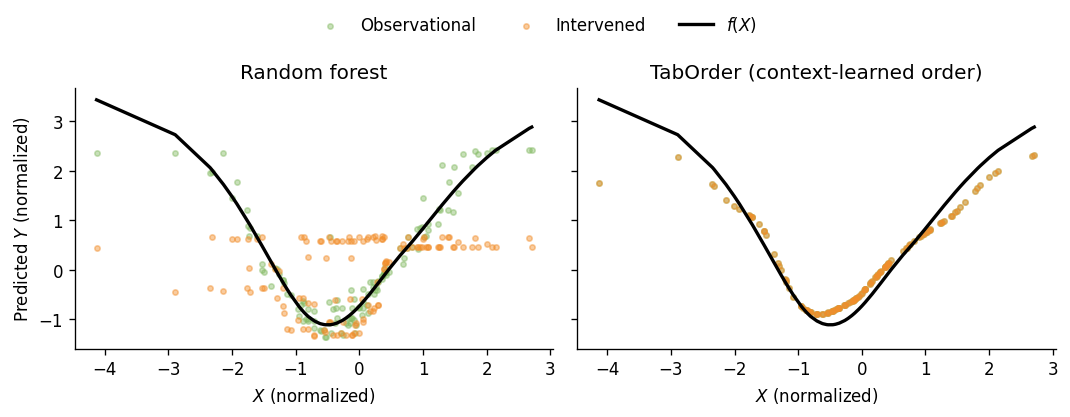

In [5]:
intervention_predictions, intervention_metrics, learned_order = intervention_experiment(
    gp_model, seed=20, n_context=128, n_query=128,
    run_tabpfn=RUN_TABPFN, tabpfn_model_path=TABPFN_MODEL_PATH,
)
print("Order inferred from context:", " -> ".join(["X", "Y", "Z"][i] for i in learned_order))
print("Reference generating order: X -> Y -> Z (not provided to the model)")
if learned_order != [0, 1, 2]:
    print("The learned order differs on this draw; the result is retained without changing the seed or using an oracle.")
print(intervention_metrics.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
intervention_predictions.to_csv(OUT / "intervention_predictions.csv", index=False)
intervention_metrics.to_csv(OUT / "intervention_metrics.csv", index=False)
methods = ["Random forest", "TabOrder (context-learned order)"]
if RUN_TABPFN:
    methods.insert(0, "TabPFN (fresh run)")
fig, axes = plt.subplots(1, len(methods), figsize=(4.5 * len(methods), 3.5), sharex=True, sharey=True)
for ax, method in zip(axes, methods):
    group = intervention_predictions[intervention_predictions.method == method]
    for condition, color in [("Observational", "#85bb65"), ("Intervened", "#f28e2b")]:
        subset = group[group.condition == condition]
        ax.scatter(subset.x, subset.predicted_y, s=10, alpha=0.45, color=color, label=condition)
    truth = group[group.condition == "Observational"].sort_values("x")
    ax.plot(truth.x, truth.y_noisefree, color="black", linewidth=2, label="$f(X)$")
    ax.set(title=method, xlabel="$X$ (normalized)")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Predicted $Y$ (normalized)")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.90))
fig.savefig(OUT / "intervention_live.png", bbox_inches="tight")
fig.savefig(OUT / "intervention_live.pdf", bbox_inches="tight")
plt.show()


## Artifacts and reproducibility

The cells write Figure 1 as PNG/PDF, fresh experiment plots, per-seed CSVs, and
run metadata under `outputs/intro/`. Keep the per-seed rows when increasing the
number of runs or changing the data: a single illustrative chain is not a
benchmark-wide robustness claim.

For your own continuous table, use `taborder.impute_table(model, values,
missing_mask, context_size=...)`. The helper fits normalization only on observed
context values, ignores hidden truth, and returns values in original units.
At least one observed context entry is required in every column.


In [6]:
from importlib.metadata import version

metadata = {
    "seed": SEED, "chain_seed": 20, "device": DEVICE,
    "order_seeds": list(ORDER_SEEDS), "imputation_seeds": list(IMPUTATION_SEEDS),
    "context_rows": 128, "intervention_query_rows": 128,
    "fresh_tabpfn": RUN_TABPFN, "learned_chain_order": learned_order,
    "versions": {name: version(name) for name in ["torch", "numpy", "pandas", "matplotlib", "scikit-learn"]},
    "checkpoints": {p.name: hashlib.sha256(p.read_bytes()).hexdigest()
                    for p in sorted((ROOT / "checkpoints").glob("*.pth"))},
    "paper_prediction_sha256": figure_manifest["sha256"],
}
if RUN_TABPFN:
    metadata["versions"]["tabpfn"] = version("tabpfn")
(OUT / "run_metadata.json").write_text(json.dumps(metadata, indent=2) + "\n")
print("Saved artifacts in outputs/intro/")


Saved artifacts in outputs/intro/
